In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt 
from scipy.optimize import minimize 
from IPython.display import display

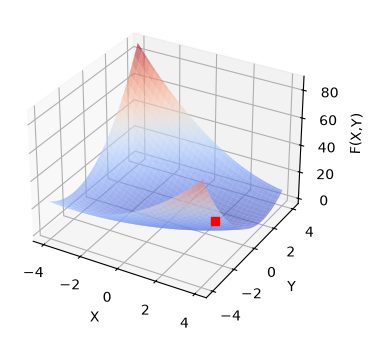

In [3]:
xn = np.linspace(-4, 4, 101)
yn = np.linspace(-4, 4, 101)
X, Y = np.meshgrid(xn, yn)
F = X**2 + 2 * Y**2 -  2* X * Y - 2 * X 

imin = np.argmin(F)
Xmin = X.flat[imin]
Ymin = Y.flat[imin]
Fmin = F.flat[imin]

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X,Y,F, cmap="coolwarm", alpha=0.6)
ax.plot(Xmin, Ymin, Fmin, "rs", zorder =10)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("F(X,Y)")

plt.show()

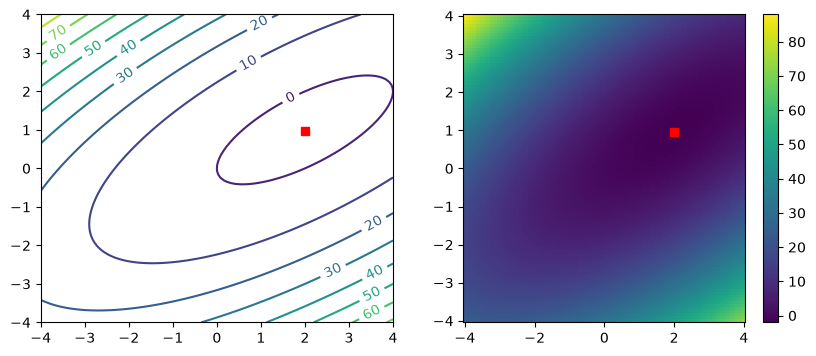

In [5]:
fig, axs = plt.subplots(1,2 , figsize=(10,4))

p1 = axs[0].contour(X,Y,F, levels=10)
axs[0].clabel(p1)

p2 = axs[1].pcolormesh(X,Y,F)
fig.colorbar(p2, ax=axs[1])

for ax in axs:
    ax.plot(Xmin, Ymin, "rs")
fig.savefig("fxy.png", dpi=300)
plt.show()


In [8]:
def f(xy):
    x, y = xy 
    return x**2 + 2 * y**2 - 2*x*y - 2*x

res = minimize (f, [0,0])
# print(res)
print(f"min (x,y) at {res.x} with f({res.x})={res.fun}")

min (x,y) at [1.99999988 0.99999999] with f([1.99999988 0.99999999])=-1.9999999999999867


In [ ]:
x,y = sp.symbols("x y")
f = x**2 + 2 * y**2 - 2*x*y - 2*x

grad =[ f.diff(x), f.diff(y)]
sol = sp.solve(grad, (x,y), dict=True)
Hess = sp.hessian(f, (x,y))

for s in sol:
    H = Hess.subs(s)
    fxx =  H[0,0]
    if H.det()>0 :
        if fxx>0:
            print(f"{s} is local min")
        else:
            print(f"{s} is local max")
    elif H.det()<0:
        print(f"{s} is saddle point")
    else:
        print("test fails")

{x: 2, y: 1} is local min
